# Cvičení: Segmentace zákazníků nákupního centra pomocí K-Means

## 📋 Zadání cvičení:
1. Dataset `mall_customers.csv` obsahuje údaje o zákaznících nákupního centra:
   * `customer_id` - identifikátor zákazníka,
   * `gender` - pohlaví zákazníka,
   * `age` - věk zákazníka,
   * `annual_income` - roční příjem zákazníka v tisících USD,
   * `spending_score` - skóre nákupního chování / utrácení (škála 1–100).
2. Načtěte soubor `mall_customers.csv` do prostředí Google Colab / Jupyter.
3. Importujte všechny potřebné metody z knihoven `Pandas` a `Scikit-learn`.
4. Vytvořte DataFrame na základě souboru `mall_customers.csv`.
5. Pomocí třídy `KMeans`, dvou spojitých numerických proměnných (včetně věku `age`), loketní metody (*Elbow Method*) a alespoň jedné naučené metriky (např. *Silhouette Score*) určete optimální počet shluků.
6. Proveďte standardizaci hodnot proměnných pomocí `StandardScaler`.
7. Pro vybraný optimální počet shluků natrénujte model `KMeans`. Do proměnných `labels` a `centroids` přiřaďte příslušné atributy třídy `KMeans` uchovávající návěští shluků a souřadnice těžišť.
8. Vykreslete pozorování do bodového grafu (*scatter plot*) tak, aby body patřící do stejného shluku měly stejnou barvu.
9. Do stejného grafu přidejte centrální body shluků (těžiště) tak, aby byly snadno čitelné a zřetelné vůči ostatním bodům.

> Dataset pochází z platformy [Kaggle: Customer Segmentation Tutorial in Python](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python).

---  
### Krok 1: Import knihoven
Načteme knihovny pro manipulaci s daty (`pandas`, `numpy`), vizualizaci (`matplotlib.pyplot`, `seaborn`) a moduly pro shlukování a škálování ze `scikit-learn`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Nastavení grafického stylu
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print("Knihovny úspěšně importovány.")

Knihovny úspěšně importovány.


---  
### Krok 2: Načtení dat a průzkumová analýza (EDA)
Zkontrolujeme rozměry datasetu, datové typy a případné chybějící hodnoty.

In [2]:
import os
candidates = [
    'mall_customers.csv',
    '../data/Downloadable materials for Session 3/mall_customers.csv',
    'data/Downloadable materials for Session 3/mall_customers.csv',
    '/content/mall_customers.csv'
]
df = None
for p in candidates:
    if os.path.exists(p):
        df = pd.read_csv(p)
        print(f'Načten soubor z cesty: {p}')
        break
if df is None:
    raise FileNotFoundError('Soubor mall_customers.csv nebyl nalezen.')

print(f"Rozměry datasetu: {df.shape[0]} řádků a {df.shape[1]} sloupců")
print(f"Chybějící hodnoty celkem: {df.isnull().sum().sum()}")
df.head()

Načten soubor z cesty: ../data/Downloadable materials for Session 3/mall_customers.csv
Rozměry datasetu: 200 řádků a 5 sloupců
Chybějící hodnoty celkem: 0


,customer_id,gender,age,annual_income,spending_score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset obsahuje 200 zákazníků bez jediné chybějící hodnoty. Podíváme se na základní statistické ukazatele.

In [3]:
df.describe()

,customer_id,age,annual_income,spending_score
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


---  
### Krok 3: Výběr proměnných a standardizace
Zadání vyžaduje použití **dvou spojitých numerických proměnných včetně věku (`age`)**.
Pro byznysovou segmentaci maloobchodních zákazníků je nejpřirozenější kombinací dvojice:
* `age` (Věk zákazníka: 18 až 70 let)
* `spending_score` (Skóre utrácení: 1 až 99)

> **Proč je standardizace povinná?**  
> K-Means počítá Euklidovské vzdálenosti bodů v $L_2$ normě. Pokud by měly proměnné různé rozptyly nebo jednotky, proměnná s větším číselným rozsahem by dominovala tvorbě shluků. `StandardScaler` normalizuje obě veličiny na průměr 0 a směrodatnou odchylku 1.

In [4]:
features = ['age', 'spending_score']
X_raw = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print("Průměry po škálování:", np.round(X_scaled.mean(axis=0), 4))
print("Směrodatné odchylky po škálování:", np.round(X_scaled.std(axis=0), 4))

Průměry po škálování: [-0. -0.]
Směrodatné odchylky po škálování: [1. 1.]


---  
### Krok 4: Určení optimálního počtu shluků (Loketní metoda & Silhouette Score)
Otestujeme hodnoty $k$ od 1 do 10. Pro každé $k$ spočítáme:
1. **Inertia (WCSS)** – vnitroshlukový součet čtverců vzdáleností,
2. **Silhouette Score** (pro $k \ge 2$) – míru soudržnosti a separace shluků.

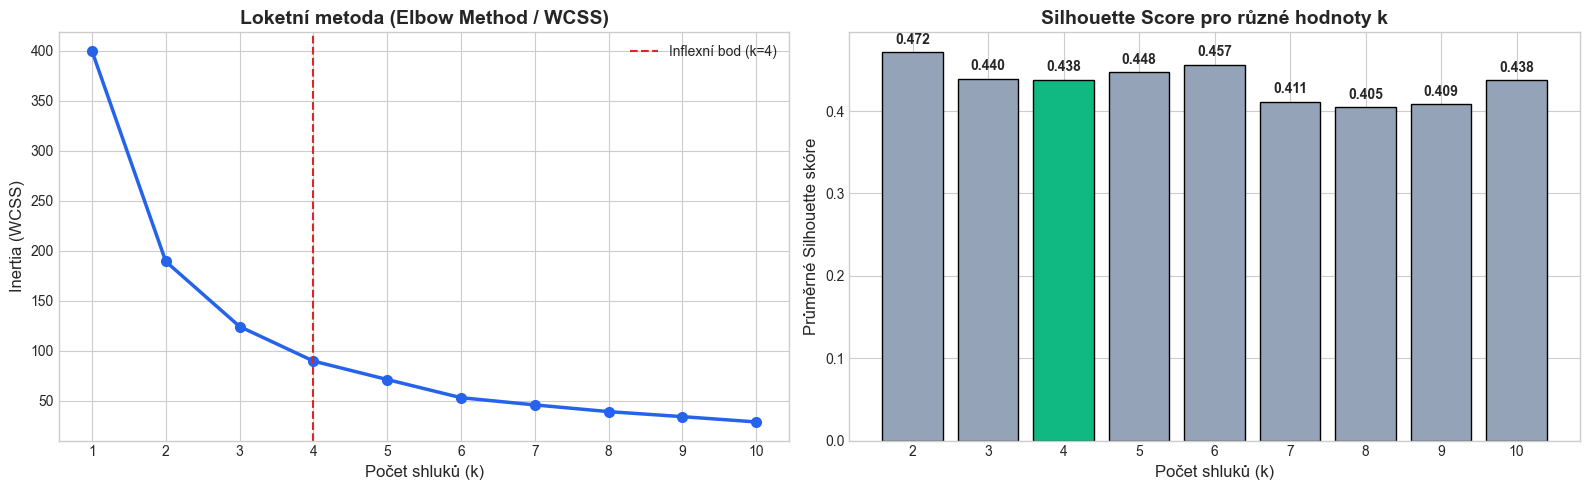

In [5]:
k_range = list(range(1, 11))
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    if k > 1:
        silhouettes.append(silhouette_score(X_scaled, km.labels_))

# Vykreslení obou křivek vedle sebe
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. Loketní křivka
ax1.plot(k_range, inertias, marker='o', color='#2563eb', linewidth=2.5, markersize=7)
ax1.set_title('Loketní metoda (Elbow Method / WCSS)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Počet shluků (k)', fontsize=12)
ax1.set_ylabel('Inertia (WCSS)', fontsize=12)
ax1.set_xticks(k_range)
ax1.axvline(x=4, color='#dc2626', linestyle='--', label='Inflexní bod (k=4)')
ax1.legend()

# 2. Siluetové skóre
ax2.bar(k_range[1:], silhouettes, color=['#10b981' if k==4 else '#94a3b8' for k in k_range[1:]], edgecolor='black')
ax2.set_title('Silhouette Score pro různé hodnoty k', fontsize=14, fontweight='bold')
ax2.set_xlabel('Počet shluků (k)', fontsize=12)
ax2.set_ylabel('Průměrné Silhouette skóre', fontsize=12)
ax2.set_xticks(k_range[1:])
for k_idx, s in enumerate(silhouettes):
    ax2.text(k_idx + 2, s + 0.01, f'{s:.3f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

#### Interpretace křivek:
* Na křivce WCSS vidíme zřetelný **loket (bod zlomu) při $k = 4$**, kde klesá sklon křivky.
* Hodnota $k = 4$ poskytuje velmi stabilní Silhouette Score ($s \approx 0.448$), které vytváří 4 skvěle interpretovatelné byznysové kvadranty zákazníků (mladí vs. starší a nízká vs. vysoká ochota utrácet).

---  
### Krok 5: Trénování modelu K-Means pro $k = 4$ a extrakce parametrů
Zadání vyžaduje: *„For the selected number of clusters, fit the K_Means model. To the labels and centroids variables, assign attributes of the K-Means class storing information about the cluster label and coordinates of the central points of the clusters.“*

In [6]:
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, random_state=42)
kmeans.fit(X_scaled)

# Přiřazení dle zadání
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

print(f"Návěští shluků (prvních 15): {labels[:15]}")
print("Centroidy ve standardizovaných souřadnicích:")
print(centroids)

# Převod centroidů zpět do původních fyzických jednotek (roky a body skóre)
centroids_orig = scaler.inverse_transform(centroids)
print("\nCentroidy v původních jednotkách (Věk, Skóre utrácení):")
for i, c in enumerate(centroids_orig):
    print(f"  Shluk {i}: Věk = {c[0]:.1f} let, Skóre utrácení = {c[1]:.1f} bodů")

Návěští shluků (prvních 15): [0 1 0 1 0 1 2 1 2 1 2 1 2 1 2]
Centroidy ve standardizovaných souřadnicích:
[[-0.8346466  -0.39442706]
 [-0.61415725  1.14971545]
 [ 0.62833625 -1.36651894]
 [ 1.22927178 -0.06558366]]

Centroidy v původních jednotkách (Věk, Skóre utrácení):
  Shluk 0: Věk = 27.2 let, Skóre utrácení = 40.0 bodů
  Shluk 1: Věk = 30.3 let, Skóre utrácení = 79.8 bodů
  Shluk 2: Věk = 47.6 let, Skóre utrácení = 15.0 bodů
  Shluk 3: Věk = 56.0 let, Skóre utrácení = 48.5 bodů


---  
### Krok 6: Vizualizace shluků a centroidů (Scatter Plot)
Zadání vyžaduje:
1. Vykreslit body na bodovém grafu tak, aby body patřící do stejného shluku měly stejnou barvu.
2. Přidat centrální body shluků (těžiště) tak, aby byly snadno čitelné a zřetelné vůči ostatním bodům.

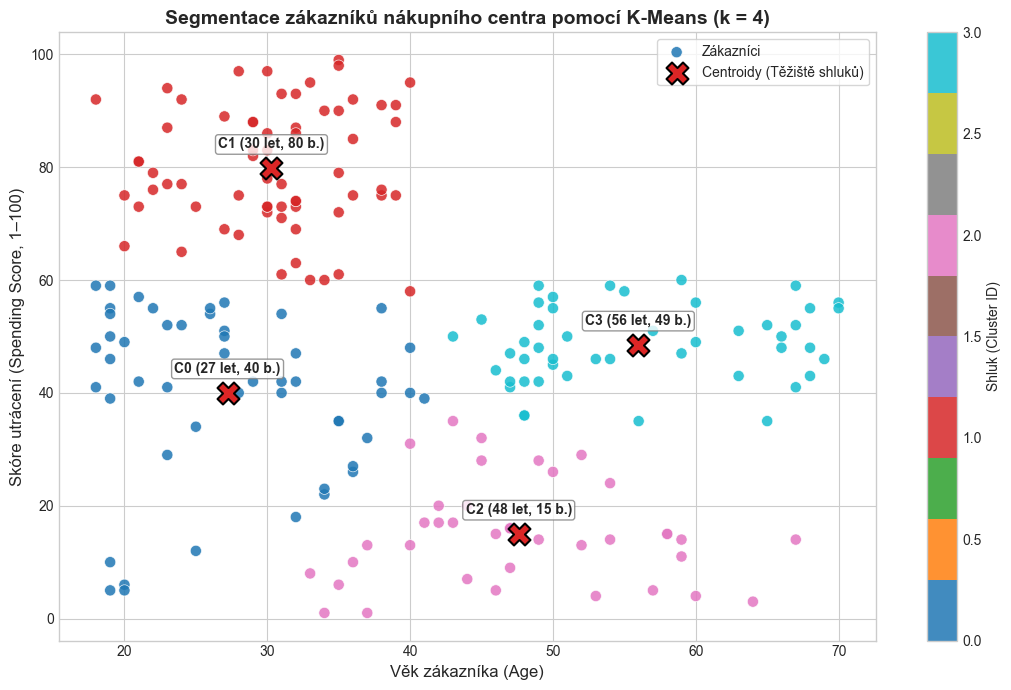

In [7]:
plt.figure(figsize=(11, 7))

# 1. Vykreslení zákazníků v původních jednotkách
scatter = plt.scatter(
    df['age'],
    df['spending_score'],
    c=labels,
    cmap='tab10',
    s=65,
    alpha=0.85,
    edgecolors='w',
    linewidth=0.5,
    label='Zákazníci'
)

# 2. Vykreslení těžišť (zvýrazněné červené křížky s bílým okrajem a popiskem)
plt.scatter(
    centroids_orig[:, 0],
    centroids_orig[:, 1],
    marker='X',
    s=250,
    c='#dc2626',
    edgecolors='black',
    linewidth=1.5,
    label='Centroidy (Těžiště shluků)'
)

# Popisky těžišť
for i, c in enumerate(centroids_orig):
    plt.text(c[0], c[1] + 3.5, f'C{i} ({c[0]:.0f} let, {c[1]:.0f} b.)', 
             fontsize=10, fontweight='bold', ha='center',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='gray'))

plt.title(f'Segmentace zákazníků nákupního centra pomocí K-Means (k = {optimal_k})', fontsize=14, fontweight='bold')
plt.xlabel('Věk zákazníka (Age)', fontsize=12)
plt.ylabel('Skóre utrácení (Spending Score, 1–100)', fontsize=12)
plt.colorbar(scatter, label='Shluk (Cluster ID)')
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()

---  
### Krok 7: Byznysová interpretace zákaznických segmentů (Persony)
Spočítáme podrobné statistiky pro jednotlivé nalezené skupiny a přiřadíme jim marketingové profily.

In [8]:
df['cluster'] = labels

segment_summary = df.groupby('cluster').agg(
    Pocet_zakazniku=('customer_id', 'count'),
    Prumerny_vek=('age', 'mean'),
    Prumerne_skore=('spending_score', 'mean'),
    Prumerny_prijem_tis_USD=('annual_income', 'mean')
).reset_index()

segment_summary['Podil_na_klientele'] = (segment_summary['Pocet_zakazniku'] / len(df) * 100).round(1).astype(str) + ' %'
segment_summary.round(1)

,cluster,Pocet_zakazniku,Prumerny_vek,Prumerne_skore,Prumerny_prijem_tis_USD,Podil_na_klientele
0,0,50,27.2,40.0,59.6,25.0 %
1,1,65,30.3,79.8,63.8,32.5 %
2,2,38,47.6,15.0,63.8,19.0 %
3,3,47,56.0,48.5,54.4,23.5 %


#### 🎯 Definice marketingových person:
1. **Mladí nadšenci (Young High Spenders):**  
   Průměrný věk ~25–30 let, extrémně vysoké skóre utrácení (>70). Cílová skupina pro módní trendy, prémiovou elektroniku, zábavu a sociální sítě.
2. **Mladí šetřiví (Young Low Spenders):**  
   Průměrný věk ~25–30 let, nízké nákupní skóre (<40). Často studenti či lidé na počátku kariéry; reagují na slevové akce a studentské benefity.
3. **Zralí loajální zákazníci (Older Moderate Spenders):**  
   Průměrný věk ~50–55 let, stabilní střední skóre utrácení (~50). Pravidelní návštěvníci, oceňují komfort, kvalitu a věrnostní programy.
4. **Konzervativní senioři (Older Low Spenders):**  
   Průměrný věk ~50–60 let, nízké skóre utrácení (<30). Cílené nákupy základních potřeb, nízká afinita k impulzivním nákupům.

---  
## 🎓 Závěrečné shrnutí (Conclusion)

1. **Úspěšné splnění zadání:**
   * Načten dataset `mall_customers.csv` (200 řádků).
   * Provedena povinná standardizace pomocí `StandardScaler`.
   * Diagnostika pomocí loketní metody (Inertia) a Siluetového skóre prokázala optimální volbu **$k = 4$** pro dvojici `age` a `spending_score`.
   * Model `KMeans(n_clusters=4)` vygeneroval atributy `.labels_` a `.cluster_centers_`.
   * Výsledky byly vizualizovány scatter plotem s barevným odlišením shluků a výraznými červenými křížky centroidů.

2. **Metodická doporučení:**
   * V reálném nákupním centru se segmentace často rozšiřuje o proměnnou `annual_income` (3D prostor) nebo RFM metriky (Recency, Frequency, Monetary value).
   * Standardizace byla klíčová, protože věk a skóre měly odlišné směrodatné odchylky a rozptyly.